# Tace vs Systemic sequencing analysis in LATE stage HCC patients

## Data Preperation

In [814]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('hcc_TACE_Sys_Cov.csv')

#Removed stage as a covariate
covariates = [
    'AGE', 'SEX', 'RACE', 'HISPANIC', #Demographics
    'INSURANCE_STATUS', 'MEDIAN_INCOME',#Socioeconomic
    'Charlson_Deyo_Score', 'HISTOLOGY',#Clinical
    'YEAR_OF_DIAGNOSIS' #Temporal
]

df.shape

(1227, 341)

In [815]:
df['COMBINED_STAGE_GROUP'].value_counts()

COMBINED_STAGE_GROUP
4    485
3    467
2    178
1     97
Name: count, dtype: int64

In [816]:
#Keep only early stage HCC patients
df = df[df['COMBINED_STAGE_GROUP'] == 4]

In [817]:
df.shape

(485, 341)

## Propensity Score

In [818]:
from sklearn.linear_model import LogisticRegression

# One-hot encode categorical covariates
df_encoded = pd.get_dummies(df[covariates], drop_first=True)
X = df_encoded
y = df['sequence_group']

ps_model = LogisticRegression(max_iter=2000)
ps_model.fit(X, y)

df['ps'] = ps_model.predict_proba(X)[:, 1]

## IPTW

### IPTW Weights

In [819]:
df['iptw_weight'] = df.apply(
    lambda row: 1 / row['ps'] if row['sequence_group'] == 1 else 1 / (1 - row['ps']),
    axis=1
)

#df = df[df['iptw_weight'] < 12]

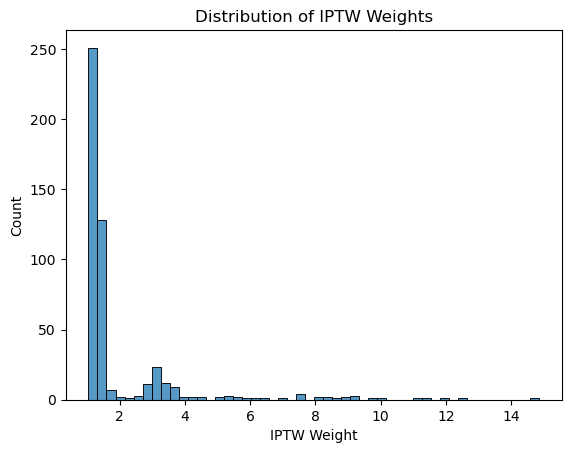

In [820]:
sns.histplot(df['iptw_weight'], bins=50)
plt.title("Distribution of IPTW Weights")
plt.xlabel("IPTW Weight")
plt.ylabel("Count")
plt.show()

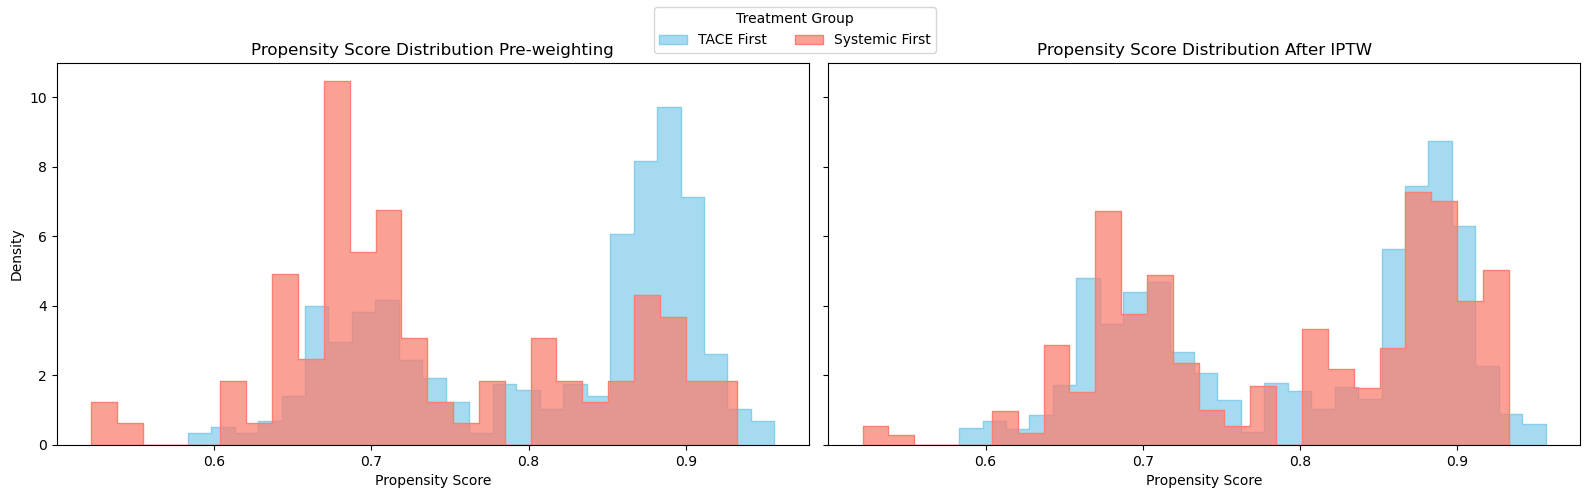

In [821]:
# Create a figure with two subplots side by side
fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)

# Plot 1: Propensity Score Distribution Pre-weighting
sns.histplot(
    data=df[df['sequence_group'] == 1],
    x='ps', bins=25, stat='density',
    color='skyblue', label='TACE First', element='step',
    ax=axes[0]
)
sns.histplot(
    data=df[df['sequence_group'] == 0],
    x='ps', bins=25, stat='density',
    color='salmon', label='Systemic First', element='step',
    ax=axes[0]
)
axes[0].set_title("Propensity Score Distribution Pre-weighting")
axes[0].set_xlabel("Propensity Score")
axes[0].set_ylabel("Density")

# Plot 2: Propensity Score Distribution After IPTW
sns.histplot(
    data=df[df['sequence_group'] == 1],
    x='ps', weights='iptw_weight', bins=25, stat='density',
    color='skyblue', label='TACE First', element='step',
    ax=axes[1]
)
sns.histplot(
    data=df[df['sequence_group'] == 0],
    x='ps', weights='iptw_weight', bins=25, stat='density',
    color='salmon', label='Systemic First', element='step',
    ax=axes[1]
)
axes[1].set_title("Propensity Score Distribution After IPTW")
axes[1].set_xlabel("Propensity Score")

# Add a single legend for both plots
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=2, title="Treatment Group")

# Adjust layout
plt.tight_layout(rect=[0, 0, 1, 0.95])  # Leave space for the legend
plt.show()

### ASMD

In [822]:
def compute_asmd(df, covariate, treatment_col, weight_col=None):
    groups = df[treatment_col].unique()
    g1 = df[df[treatment_col] == groups[0]]
    g2 = df[df[treatment_col] == groups[1]]

    if weight_col is None:
        w1 = np.ones(len(g1))
        w2 = np.ones(len(g2))
    else:
        w1 = g1[weight_col].values
        w2 = g2[weight_col].values

    def weighted_mean_std(x, w):
        mean = np.average(x, weights=w)
        var = np.average((x - mean)**2, weights=w)
        return mean, np.sqrt(var)

    if df[covariate].dtype in [np.float64, np.int64]:
        m1, s1 = weighted_mean_std(g1[covariate], w1)
        m2, s2 = weighted_mean_std(g2[covariate], w2)
        pooled_sd = np.sqrt((s1**2 + s2**2)/2)
        asmd = abs(m1 - m2) / pooled_sd
    else:
        # Categorical variable: use dummy encoding
        dummies = pd.get_dummies(df[covariate], drop_first=False)
        asmd_list = []
        for level in dummies.columns:
            x1 = dummies.loc[g1.index, level]
            x2 = dummies.loc[g2.index, level]
            m1 = np.average(x1, weights=w1)
            m2 = np.average(x2, weights=w2)
            pooled = (m1*(1 - m1) + m2*(1 - m2)) / 2
            asmd = abs(m1 - m2) / np.sqrt(pooled) if pooled > 0 else 0
            asmd_list.append(asmd)
        asmd = np.mean(asmd_list)
    return asmd


In [823]:
asmd_unweighted = []
asmd_weighted = []

for covariate in covariates:
    try:
        a1 = compute_asmd(df, covariate, 'sequence_group', weight_col=None)
        a2 = compute_asmd(df, covariate, 'sequence_group', weight_col='iptw_weight')
    except Exception as e:
        print(f"Skipping {covariate}: {e}")
        continue
    asmd_unweighted.append(a1)
    asmd_weighted.append(a2)

asmd_df = pd.DataFrame({
    'Covariate': covariates,
    'Unweighted': asmd_unweighted,
    'IPTW': asmd_weighted
})

asmd_df.sort_values(by='Unweighted', ascending=True, inplace=True)


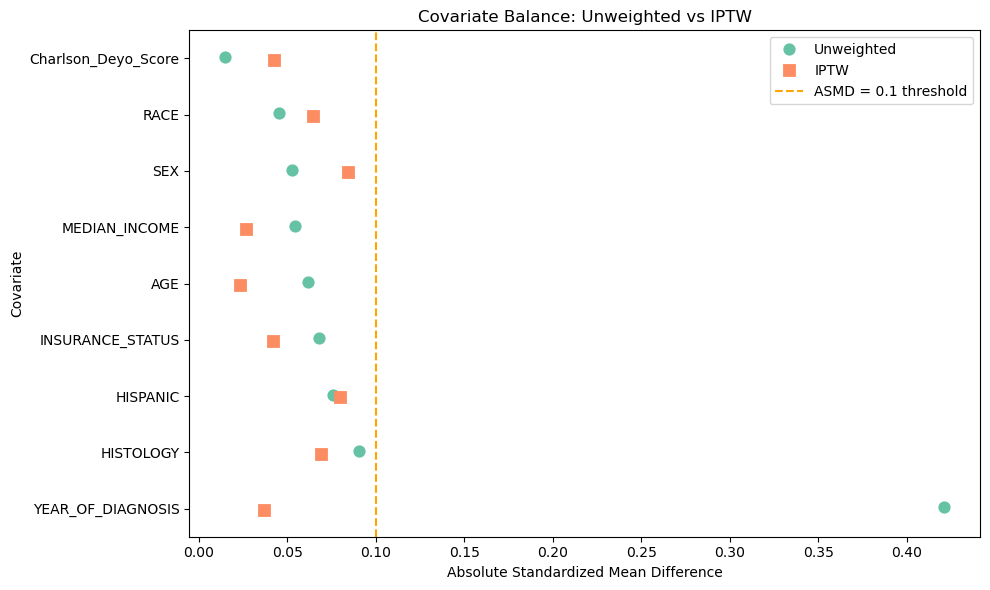

In [824]:
asmd_df_melted = asmd_df.melt(id_vars='Covariate', var_name='Method', value_name='ASMD')

plt.figure(figsize=(10, 6))
sns.pointplot(
    data=asmd_df_melted,
    x='ASMD',
    y='Covariate',
    hue='Method',
    dodge=True,  # Separate points for each method
    linestyle='none',  # Do not connect points with lines
    markers=["o", "s", "D"],  # Optional: Different markers for clarity
    palette="Set2"  # Optional: Custom color palette
)
plt.axvline(0.1, linestyle='--', color='orange', label='ASMD = 0.1 threshold')
plt.xlabel("Absolute Standardized Mean Difference")
plt.title("Covariate Balance: Unweighted vs IPTW")
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

### Cox

In [825]:
df['sequence_group'].value_counts()

sequence_group
1    386
0     99
Name: count, dtype: int64

In [826]:
from lifelines import CoxPHFitter

df_cox = df[['time', 'event', 'sequence_group', 'iptw_weight']].copy()

cph = CoxPHFitter()
cph.fit(df_cox, duration_col='time', event_col='event', weights_col='iptw_weight')
cph.print_summary()



/Users/nicolaszhang/miniconda3/envs/data_science_env/lib/python3.12/site-packages/lifelines/fitters/coxph_fitter.py:1356: StatisticalWarning: It appears your weights are not integers, possibly propensity or sampling scores then?
It's important to know that the naive variance estimates of the coefficients are biased. Instead a) set `robust=True` in the call to `fit`, or b) use Monte Carlo to
estimate the variances. See paper "Variance estimation when using inverse probability of treatment weighting (IPTW) with survival analysis"

  warnings.warn(


<lifelines.CoxPHFitter: fitted with 959.726 total observations, 263.068 right-censored observations>
             duration col = 'time'
                event col = 'event'
              weights col = 'iptw_weight'
      baseline estimation = breslow
   number of observations = 959.726
number of events observed = 696.659
   partial log-likelihood = -4298.88
         time fit was run = 2025-05-28 16:31:07 UTC

---
                coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                       
sequence_group  0.25      1.28      0.08            0.10            0.40                1.10                1.49

                cmp to    z      p  -log2(p)
covariate                                   
sequence_group    0.00 3.24 <0.005      9.73
---
Concordance = 0.52
Partial AIC = 8599.76
log-likelihood ratio test = 10.58 on 1 df
-log2(p) of ll-ratio test = 9.77

### Kaplan_Meier

In [827]:
df['group_label'] = df['sequence_group'].map({0: 'Systemic First', 1: 'TACE First'})
df['group_label'].value_counts()

group_label
TACE First        386
Systemic First     99
Name: count, dtype: int64

In [828]:
from lifelines import KaplanMeierFitter

mask_tace = df['sequence_group'] == 1
mask_sys = df['sequence_group'] == 0

# Initialize fitters
kmf_tace = KaplanMeierFitter()
kmf_sys = KaplanMeierFitter()

# Fit each group with weights
kmf_tace.fit(
    durations=df.loc[mask_tace, 'time'],
    event_observed=df.loc[mask_tace, 'event'],
    weights=df.loc[mask_tace, 'iptw_weight'],
    label="TACE First"
)

kmf_sys.fit(
    durations=df.loc[mask_sys, 'time'],
    event_observed=df.loc[mask_sys, 'event'],
    weights=df.loc[mask_sys, 'iptw_weight'],
    label="Systemic First"
)

/Users/nicolaszhang/miniconda3/envs/data_science_env/lib/python3.12/site-packages/lifelines/fitters/kaplan_meier_fitter.py:338: StatisticalWarning: It looks like your weights are not integers, possibly propensity scores then?
  It's important to know that the naive variance estimates of the coefficients are biased. Instead use Monte Carlo to
  estimate the variances. See paper "Variance estimation when using inverse probability of treatment weighting (IPTW) with survival analysis"
  or "Adjusted Kaplan-Meier estimator and log-rank test with inverse probability of treatment weighting for survival data."
                  
  warnings.warn(
/Users/nicolaszhang/miniconda3/envs/data_science_env/lib/python3.12/site-packages/lifelines/fitters/kaplan_meier_fitter.py:338: StatisticalWarning: It looks like your weights are not integers, possibly propensity scores then?
  It's important to know that the naive variance estimates of the coefficients are biased. Instead use Monte Carlo to
  estimate

<lifelines.KaplanMeierFitter:"Systemic First", fitted with 475.91 total observations, 157.236 right-censored observations>

### Weighted Number at Risk

In [829]:
time_grid = np.arange(0, 73, 12)

def weighted_risk_counts(df, time_points, group_value):
    risk_counts = []
    group = df[df['sequence_group'] == group_value]
    for t in time_points:
        still_at_risk = group[group['time'] >= t]['iptw_weight'].sum()
        risk_counts.append(int(round(still_at_risk)))
    return risk_counts

tace_risk = weighted_risk_counts(df, time_grid, 1)
sys_risk = weighted_risk_counts(df, time_grid, 0)



### 3 & 5 Year Survival

In [830]:
def survival_with_ci(kmf, time):
    surv = kmf.predict(time)
    
    closest_idx = kmf.confidence_interval_.index.get_indexer([time], method='nearest')[0]
    ci = kmf.confidence_interval_.iloc[closest_idx]

    lower = ci.iloc[0]
    upper = ci.iloc[1]

    # sanity check for CI
    if (upper == 1.0 and lower == 1.0) or (upper == 0.0 and lower == 0.0):
        return surv, None, None  # invalid or non-estimable CI

    return surv, lower, upper

for t in [36, 60]:
    surv_sys, low_sys, high_sys = survival_with_ci(kmf_sys, t)
    surv_tace, low_tace, high_tace = survival_with_ci(kmf_tace, t)


    print(f"\nTime: {t} months")
    print(f"TACE First:     {surv_tace:.1%} ({low_tace:.1%} – {high_tace:.1%})")
    if low_sys is None or high_sys is None:
        print(f"Systemic First: {surv_sys:.1%} (CI not estimable)")
    else:
        print(f"Systemic First: {surv_sys:.1%} ({low_sys:.1%} – {high_sys:.1%})")





Time: 36 months
TACE First:     17.5% (13.8% – 21.5%)
Systemic First: 28.2% (23.8% – 32.7%)

Time: 60 months
TACE First:     11.2% (7.4% – 15.9%)
Systemic First: 24.3% (CI not estimable)


### Plot

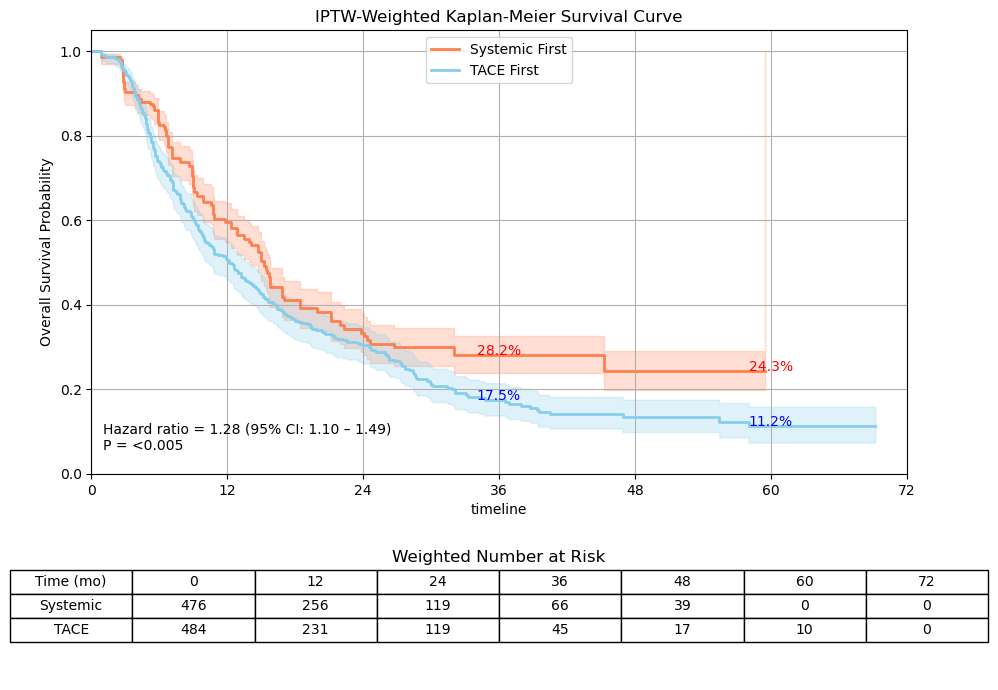

In [831]:
# 3-year and 5-year survival annotations
surv_text = {
    "Systemic First": {
        36: "28.2%",
        60: "24.3%"
    },
    "TACE First": {
        36: "17.5%",
        60: "11.2%"
    }
}

# Cox model results
hr = 1.28
ci_low = 1.10
ci_high = 1.49
p_val = '<0.005'

import matplotlib.gridspec as gridspec
# Set up the plot
fig = plt.figure(figsize=(10, 7))
gs = gridspec.GridSpec(2, 1, height_ratios=[3, 1])

# --- KM Curve (Top Panel) ---
ax_km = plt.subplot(gs[0])

months = np.linspace(0, 72, 73)
kmf_sys.plot(ax=ax_km, ci_show=True, color="coral", linewidth=2)
kmf_tace.plot(ax=ax_km, ci_show=True, color="skyblue", linewidth=2)

sys_surv = kmf_sys.predict(months)
tace_surv = kmf_tace.predict(months)

# Annotate survival rates at 3 and 5 years
for x in [36, 60]:
    ax_km.text(x, sys_surv[x], surv_text["Systemic First"][x], color="red", fontsize=10, ha='center')
    ax_km.text(x, tace_surv[x], surv_text["TACE First"][x], color="blue", fontsize=10, ha='center')

# Annotate Cox HR and p-value
hr_text = f"Hazard ratio = {hr:.2f} (95% CI: {ci_low:.2f} – {ci_high:.2f})\nP = {p_val}"
ax_km.text(1, 0.05, hr_text, fontsize=10, verticalalignment='bottom')

# Style the plot
ax_km.set_title("IPTW-Weighted Kaplan-Meier Survival Curve")
ax_km.set_ylabel("Overall Survival Probability")
ax_km.set_xlim(0, 72)
ax_km.set_ylim(0, 1.05)
ax_km.set_xticks(time_grid)
ax_km.grid(True)
ax_km.legend()

# --- Risk Table (Bottom Panel) ---
ax_table = plt.subplot(gs[1])
ax_table.axis("off")

# Table values
n_cols = len(time_grid)
table_data = [
    ["Time (mo)"] + [str(int(t)) for t in time_grid],
    ["Systemic"] + [str(n) for n in sys_risk[:n_cols]],
    ["TACE"] + [str(n) for n in tace_risk[:n_cols]]
]

# Render the table
risk_table = ax_table.table(
    cellText=table_data,
    cellLoc='center',
    loc='center'
)
ax_table.text(0.5, 0.8, "Weighted Number at Risk", fontsize=12,
              ha='center', transform=ax_table.transAxes)
risk_table.auto_set_font_size(False)
risk_table.set_fontsize(10)
risk_table.scale(1.2, 1.2)

plt.tight_layout()
plt.show()


## Non-weighted Survival Analysis

### Cox

In [832]:
df_cox_unweighted = df[['time', 'event', 'sequence_group']].copy()
cph_unweighted = CoxPHFitter()
cph_unweighted.fit(df_cox_unweighted, duration_col='time', event_col='event')
cph_unweighted.print_summary()

<lifelines.CoxPHFitter: fitted with 485 total observations, 117 right-censored observations>
             duration col = 'time'
                event col = 'event'
      baseline estimation = breslow
   number of observations = 485
number of events observed = 368
   partial log-likelihood = -2010.96
         time fit was run = 2025-05-28 16:31:08 UTC

---
                coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                       
sequence_group  0.28      1.33      0.14            0.01            0.55                1.01                1.74

                cmp to    z    p  -log2(p)
covariate                                 
sequence_group    0.00 2.06 0.04      4.66
---
Concordance = 0.52
Partial AIC = 4023.92
log-likelihood ratio test = 4.50 on 1 df
-log2(p) of ll-ratio test = 4.88

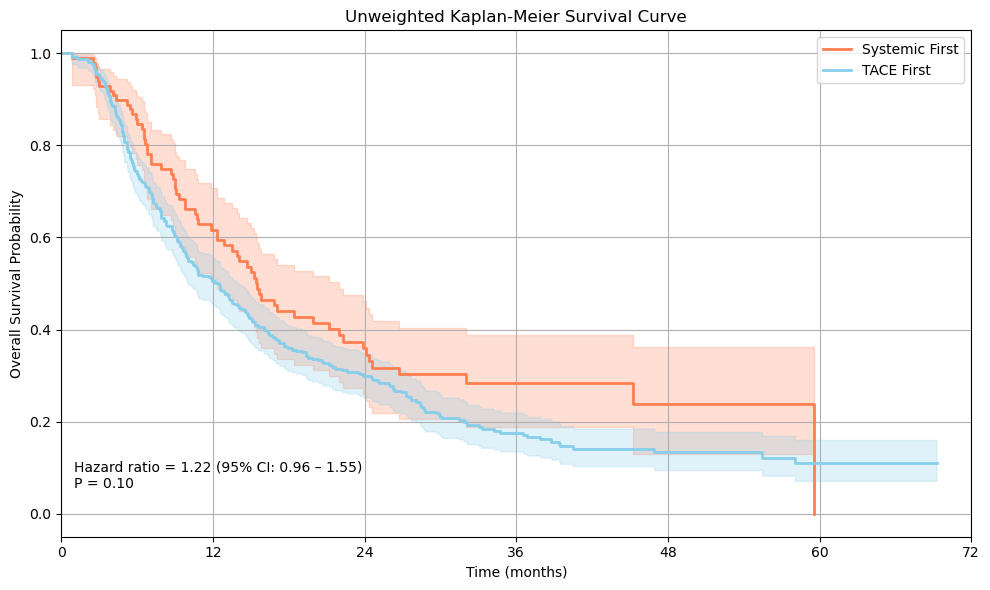

In [833]:
kmf_tace_unweighted = KaplanMeierFitter()
kmf_sys_unweighted = KaplanMeierFitter()

# Fit each group with weights
kmf_tace_unweighted.fit(
    durations=df.loc[mask_tace, 'time'],
    event_observed=df.loc[mask_tace, 'event'],
    label="TACE First"
)

kmf_sys_unweighted.fit(
    durations=df.loc[mask_sys, 'time'],
    event_observed=df.loc[mask_sys, 'event'],
    label="Systemic First"
)

# Plot unweighted KM curves
plt.figure(figsize=(10, 6))
kmf_sys_unweighted.plot(ci_show=True, color="coral", linewidth=2)
kmf_tace_unweighted.plot(ci_show=True, color="skyblue", linewidth=2)
hr_text = f"Hazard ratio = {1.22:.2f} (95% CI: {0.96:.2f} – {1.55:.2f})\nP = {0.10:.2f}"
plt.text(1, 0.05, hr_text, fontsize=10, verticalalignment='bottom')
plt.title("Unweighted Kaplan-Meier Survival Curve")
plt.ylabel("Overall Survival Probability")
plt.xlabel("Time (months)")
plt.xlim(0, 72)
plt.xticks(time_grid)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

## Subgroup analysis - Treatment Spacing

### Define subgroups

<Axes: xlabel='treatment_spacing', ylabel='Count'>

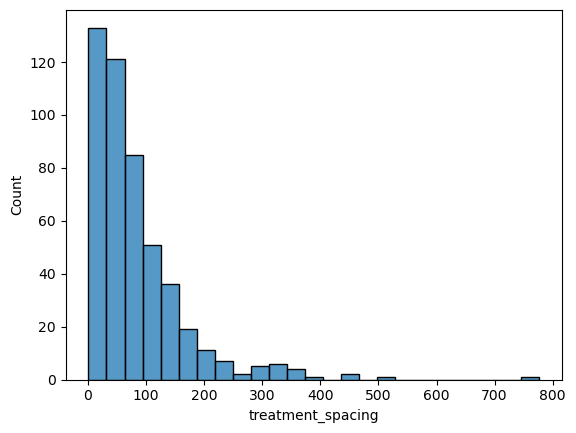

In [834]:
df['treatment_spacing'] =  abs(df['DX_CHEMO_STARTED_DAYS'] - df['DX_IMMUNO_STARTED_DAYS'])
sns.histplot(df['treatment_spacing'], bins=25)

In [835]:
df['spacing_group'] = pd.cut(
    df['treatment_spacing'],
    bins=[-1, 30, 90, np.inf],
    labels=['≤30 days', '31–90 days', '>90 days']
)

df['spacing_group'].value_counts()

spacing_group
31–90 days    202
>90 days      155
≤30 days      128
Name: count, dtype: int64

In [836]:
def km_fitter(df, sequence_group):
    mask = df['sequence_group'] == sequence_group
    kmf = KaplanMeierFitter()
    kmf.fit(
        durations=df.loc[mask, 'time'],
        event_observed=df.loc[mask, 'event'],
        weights=df.loc[mask, 'iptw_weight'],
        label="TACE First" if sequence_group == 1 else "Systemic First"
    )
    return kmf

### ≤30 days

In [837]:
df_30 = df[df['spacing_group'] == '≤30 days']

cph_30 = CoxPHFitter()
cph_30.fit(
    df_30[['time', 'event', 'sequence_group', 'iptw_weight']], 
    duration_col='time', 
    event_col='event', 
    weights_col='iptw_weight')

cph_30.print_summary()

/Users/nicolaszhang/miniconda3/envs/data_science_env/lib/python3.12/site-packages/lifelines/fitters/coxph_fitter.py:1356: StatisticalWarning: It appears your weights are not integers, possibly propensity or sampling scores then?
It's important to know that the naive variance estimates of the coefficients are biased. Instead a) set `robust=True` in the call to `fit`, or b) use Monte Carlo to
estimate the variances. See paper "Variance estimation when using inverse probability of treatment weighting (IPTW) with survival analysis"

  warnings.warn(


<lifelines.CoxPHFitter: fitted with 288.186 total observations, 79.5869 right-censored observations>
             duration col = 'time'
                event col = 'event'
              weights col = 'iptw_weight'
      baseline estimation = breslow
   number of observations = 288.186
number of events observed = 208.6
   partial log-likelihood = -1043.04
         time fit was run = 2025-05-28 16:31:08 UTC

---
                coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                       
sequence_group  0.38      1.46      0.14            0.11            0.65                1.11                1.92

                cmp to    z    p  -log2(p)
covariate                                 
sequence_group    0.00 2.72 0.01      7.25
---
Concordance = 0.54
Partial AIC = 2088.09
log-likelihood ratio test = 7.29 on 1 df
-log2(p) of ll-ratio test = 7.17

/Users/nicolaszhang/miniconda3/envs/data_science_env/lib/python3.12/site-packages/lifelines/fitters/kaplan_meier_fitter.py:338: StatisticalWarning: It looks like your weights are not integers, possibly propensity scores then?
  It's important to know that the naive variance estimates of the coefficients are biased. Instead use Monte Carlo to
  estimate the variances. See paper "Variance estimation when using inverse probability of treatment weighting (IPTW) with survival analysis"
  or "Adjusted Kaplan-Meier estimator and log-rank test with inverse probability of treatment weighting for survival data."
                  
  warnings.warn(
/Users/nicolaszhang/miniconda3/envs/data_science_env/lib/python3.12/site-packages/lifelines/fitters/kaplan_meier_fitter.py:338: StatisticalWarning: It looks like your weights are not integers, possibly propensity scores then?
  It's important to know that the naive variance estimates of the coefficients are biased. Instead use Monte Carlo to
  estimate

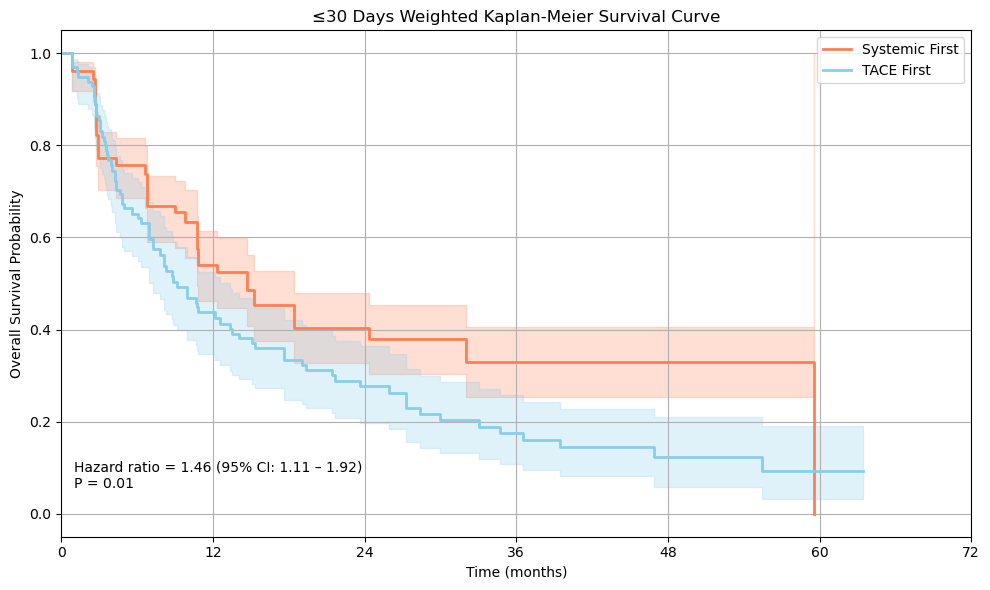

In [850]:
plt.figure(figsize=(10, 6))
km_fitter(df_30, 0).plot(ci_show=True, color="coral", linewidth=2)
km_fitter(df_30, 1).plot(ci_show=True, color="skyblue", linewidth=2)
hr_text = f"Hazard ratio = {1.46:.2f} (95% CI: {1.11:.2f} – {1.92:.2f})\nP = {0.01:.2f}"
plt.text(1, 0.05, hr_text, fontsize=10, verticalalignment='bottom')
plt.title("≤30 Days Weighted Kaplan-Meier Survival Curve")
plt.ylabel("Overall Survival Probability")
plt.xlabel("Time (months)")
plt.xlim(0, 72)
plt.xticks(time_grid)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

### 31-90 days

In [839]:
df_31_90 = df[df['spacing_group'] == '31–90 days']

cph_31_90 = CoxPHFitter()
cph_31_90.fit(
    df_31_90[['time', 'event', 'sequence_group', 'iptw_weight']], 
    duration_col='time', 
    event_col='event', 
    weights_col='iptw_weight')

cph_31_90.print_summary()

/Users/nicolaszhang/miniconda3/envs/data_science_env/lib/python3.12/site-packages/lifelines/fitters/coxph_fitter.py:1356: StatisticalWarning: It appears your weights are not integers, possibly propensity or sampling scores then?
It's important to know that the naive variance estimates of the coefficients are biased. Instead a) set `robust=True` in the call to `fit`, or b) use Monte Carlo to
estimate the variances. See paper "Variance estimation when using inverse probability of treatment weighting (IPTW) with survival analysis"

  warnings.warn(


<lifelines.CoxPHFitter: fitted with 386.96 total observations, 83.2877 right-censored observations>
             duration col = 'time'
                event col = 'event'
              weights col = 'iptw_weight'
      baseline estimation = breslow
   number of observations = 386.96
number of events observed = 303.672
   partial log-likelihood = -1589.65
         time fit was run = 2025-05-28 16:31:08 UTC

---
                coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                       
sequence_group  0.24      1.27      0.12            0.01            0.47                1.01                1.60

                cmp to    z    p  -log2(p)
covariate                                 
sequence_group    0.00 2.04 0.04      4.60
---
Concordance = 0.52
Partial AIC = 3181.31
log-likelihood ratio test = 4.19 on 1 df
-log2(p) of ll-ratio test = 4.62

/Users/nicolaszhang/miniconda3/envs/data_science_env/lib/python3.12/site-packages/lifelines/fitters/kaplan_meier_fitter.py:338: StatisticalWarning: It looks like your weights are not integers, possibly propensity scores then?
  It's important to know that the naive variance estimates of the coefficients are biased. Instead use Monte Carlo to
  estimate the variances. See paper "Variance estimation when using inverse probability of treatment weighting (IPTW) with survival analysis"
  or "Adjusted Kaplan-Meier estimator and log-rank test with inverse probability of treatment weighting for survival data."
                  
  warnings.warn(
/Users/nicolaszhang/miniconda3/envs/data_science_env/lib/python3.12/site-packages/lifelines/fitters/kaplan_meier_fitter.py:338: StatisticalWarning: It looks like your weights are not integers, possibly propensity scores then?
  It's important to know that the naive variance estimates of the coefficients are biased. Instead use Monte Carlo to
  estimate

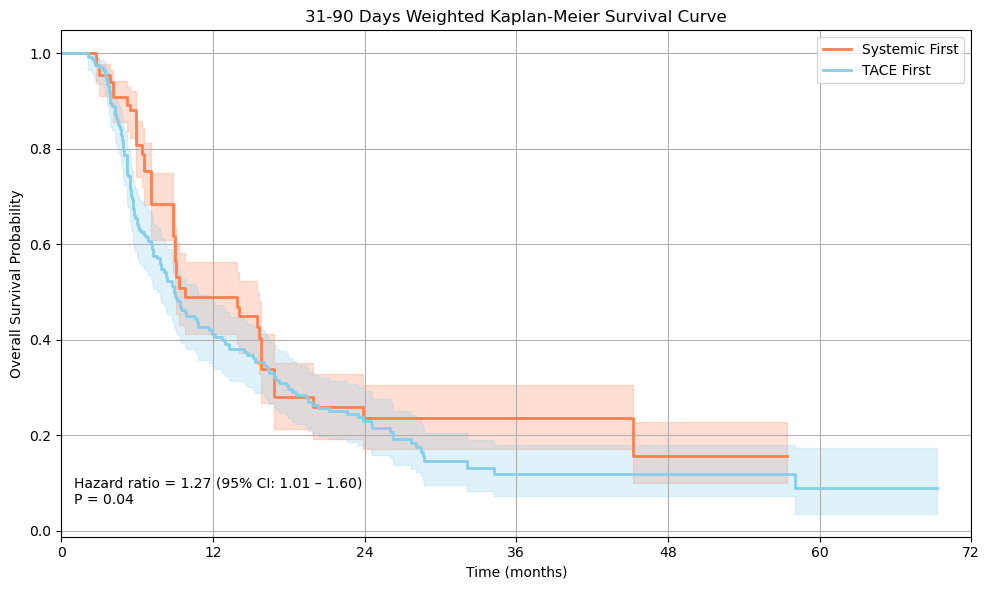

In [847]:
plt.figure(figsize=(10, 6))
km_fitter(df_31_90, 0).plot(ci_show=True, color="coral", linewidth=2)
km_fitter(df_31_90, 1).plot(ci_show=True, color="skyblue", linewidth=2)
hr_text = f"Hazard ratio = {1.27:.2f} (95% CI: {1.01:.2f} – {1.60:.2f})\nP = {0.04:.2f}"
plt.text(1, 0.05, hr_text, fontsize=10, verticalalignment='bottom')
plt.title("31-90 Days Weighted Kaplan-Meier Survival Curve")
plt.ylabel("Overall Survival Probability")
plt.xlabel("Time (months)")
plt.xlim(0, 72)
plt.xticks(time_grid)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

### >90 days

In [841]:
df_90 = df[df['spacing_group'] == '>90 days']

cph_90 = CoxPHFitter()
cph_90.fit(
    df_90[['time', 'event', 'sequence_group', 'iptw_weight']], 
    duration_col='time', 
    event_col='event', 
    weights_col='iptw_weight')

cph_90.print_summary()

/Users/nicolaszhang/miniconda3/envs/data_science_env/lib/python3.12/site-packages/lifelines/fitters/coxph_fitter.py:1356: StatisticalWarning: It appears your weights are not integers, possibly propensity or sampling scores then?
It's important to know that the naive variance estimates of the coefficients are biased. Instead a) set `robust=True` in the call to `fit`, or b) use Monte Carlo to
estimate the variances. See paper "Variance estimation when using inverse probability of treatment weighting (IPTW) with survival analysis"

  warnings.warn(


<lifelines.CoxPHFitter: fitted with 284.58 total observations, 100.193 right-censored observations>
             duration col = 'time'
                event col = 'event'
              weights col = 'iptw_weight'
      baseline estimation = breslow
   number of observations = 284.58
number of events observed = 184.387
   partial log-likelihood = -912.80
         time fit was run = 2025-05-28 16:31:08 UTC

---
                coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                       
sequence_group  0.12      1.12      0.15           -0.18            0.41                0.84                1.51

                cmp to    z    p  -log2(p)
covariate                                 
sequence_group    0.00 0.77 0.44      1.17
---
Concordance = 0.52
Partial AIC = 1827.60
log-likelihood ratio test = 0.59 on 1 df
-log2(p) of ll-ratio test = 1.18

/Users/nicolaszhang/miniconda3/envs/data_science_env/lib/python3.12/site-packages/lifelines/fitters/kaplan_meier_fitter.py:338: StatisticalWarning: It looks like your weights are not integers, possibly propensity scores then?
  It's important to know that the naive variance estimates of the coefficients are biased. Instead use Monte Carlo to
  estimate the variances. See paper "Variance estimation when using inverse probability of treatment weighting (IPTW) with survival analysis"
  or "Adjusted Kaplan-Meier estimator and log-rank test with inverse probability of treatment weighting for survival data."
                  
  warnings.warn(
/Users/nicolaszhang/miniconda3/envs/data_science_env/lib/python3.12/site-packages/lifelines/fitters/kaplan_meier_fitter.py:338: StatisticalWarning: It looks like your weights are not integers, possibly propensity scores then?
  It's important to know that the naive variance estimates of the coefficients are biased. Instead use Monte Carlo to
  estimate

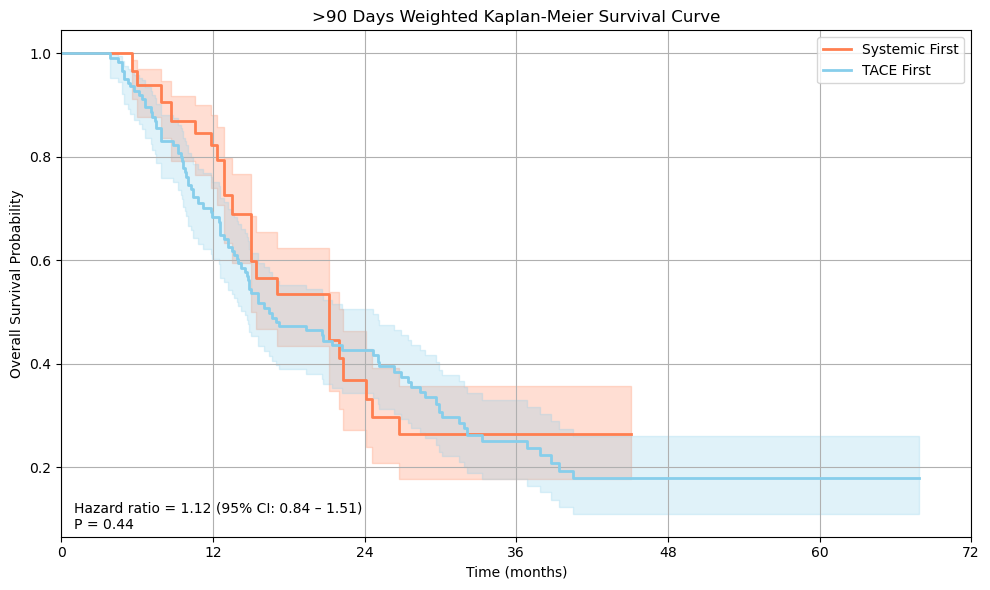

In [849]:
plt.figure(figsize=(10, 6))
km_fitter(df_90, 0).plot(ci_show=True, color="coral", linewidth=2)
km_fitter(df_90, 1).plot(ci_show=True, color="skyblue", linewidth=2)
hr_text = f"Hazard ratio = {1.12:.2f} (95% CI: {0.84:.2f} – {1.51:.2f})\nP = {0.44:.2f}"
plt.text(1, 0.075, hr_text, fontsize=10, verticalalignment='bottom')
plt.title(">90 Days Weighted Kaplan-Meier Survival Curve")
plt.ylabel("Overall Survival Probability")
plt.xlabel("Time (months)")
plt.xlim(0, 72)
plt.xticks(time_grid)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

### P-interaction and Forrest plot

In [843]:
from scipy.stats import chi2

# Fit full model (with interaction)
cph_full = CoxPHFitter()
cph_full.fit(df, duration_col='time', event_col='event',
             weights_col='iptw_weight',
             formula='sequence_group * spacing_group')

# Fit reduced model (no interaction)
cph_base = CoxPHFitter()
cph_base.fit(df, duration_col='time', event_col='event',
             weights_col='iptw_weight',
             formula='sequence_group + spacing_group')

# Perform likelihood ratio test

# log-likelihoods
ll_full = cph_full.log_likelihood_
ll_base = cph_base.log_likelihood_

# degrees of freedom = number of interaction terms
df_diff = cph_full.params_.shape[0] - cph_base.params_.shape[0]

# Likelihood ratio test statistic
lrt_stat = 2 * (ll_full - ll_base)

# P-value
p_interaction = chi2.sf(lrt_stat, df=df_diff)

print("P-interaction:", p_interaction)


/Users/nicolaszhang/miniconda3/envs/data_science_env/lib/python3.12/site-packages/lifelines/fitters/coxph_fitter.py:1356: StatisticalWarning: It appears your weights are not integers, possibly propensity or sampling scores then?
It's important to know that the naive variance estimates of the coefficients are biased. Instead a) set `robust=True` in the call to `fit`, or b) use Monte Carlo to
estimate the variances. See paper "Variance estimation when using inverse probability of treatment weighting (IPTW) with survival analysis"

  warnings.warn(


P-interaction: 0.2841621147614795


/Users/nicolaszhang/miniconda3/envs/data_science_env/lib/python3.12/site-packages/lifelines/fitters/coxph_fitter.py:1356: StatisticalWarning: It appears your weights are not integers, possibly propensity or sampling scores then?
It's important to know that the naive variance estimates of the coefficients are biased. Instead a) set `robust=True` in the call to `fit`, or b) use Monte Carlo to
estimate the variances. See paper "Variance estimation when using inverse probability of treatment weighting (IPTW) with survival analysis"

  warnings.warn(


In [844]:
def plot_forest(subgroups, hr, ci_lower, ci_upper, p_interaction=None,
                title="Subgroup Analysis", xlabel="Hazard Ratio", xlim=None):
    """
    Creates a forest plot with better layout handling.
    """
    y_pos = list(range(len(subgroups)))

    fig, ax = plt.subplots(figsize=(7, 0.5 * len(subgroups) + 1))

    # Plot horizontal CI bars
    ax.errorbar(hr, y_pos, 
                xerr=[[h - l for h, l in zip(hr, ci_lower)],
                      [u - h for u, h in zip(ci_upper, hr)]],
                fmt='o', color='teal', capsize=4)

    ax.axvline(x=1, color='gray', linestyle='--')
    ax.set_yticks(y_pos)
    ax.set_yticklabels(subgroups)
    ax.invert_yaxis()

    ax.set_xlabel(xlabel)
    ax.set_title(title)


    # Log scale, but set reasonable x-limits
    ax.set_xscale('log')
    if xlim:
        ax.set_xlim(xlim)
    else:
        ax.set_xlim([0.4, 2.5])  # typical range for HRs

    if p_interaction is not None:
        fig.text(0.02, 0.95, f"P-interaction = {p_interaction:.3f}", fontsize=10, ha='left')


    plt.subplots_adjust(left=0.35)  # ensures space for long y labels
    plt.show()

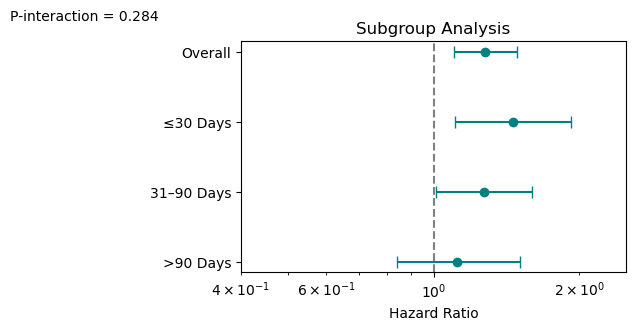

In [851]:
plot_forest(
    subgroups=["Overall", "≤30 Days", "31–90 Days", ">90 Days"],
    hr=[1.28, 1.46, 1.27, 1.12],
    ci_lower=[1.10, 1.11, 1.01, 0.84],
    ci_upper=[1.49, 1.92, 1.60, 1.51],
    p_interaction=0.284
)
